# **5. Reverse-classification validation (text → labels)**

Notebook `02` built the multilabel taxonomy from **rules**: the official disciplinary code plus explicit lexical patterns applied to normalized text. This is auditable, but it does not prove that the categories are semantically coherent in the text—it only proves that the rules match the patterns written for them.

This notebook follows the reverse path. A supervised classifier that sees only the **text** (without the official code or rules) attempts to recover the same multilabel target. Validation is always out of sample (multilabel-stratified `k`-fold), so the reported accuracy is measured on text never seen by the model that classified it. High recovery indicates that the labels carry genuine lexical signal; failures concentrated in one category indicate semantic overlap, ambiguity, or limited examples—the same audit queue as notebook `02`, now viewed from the model's perspective rather than the rule's.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

INPUT_DIR = ROOT / "data" / "processed" / "keyword_tags"
TEXTS_PATH = INPUT_DIR / "unique_text_tags.csv"
MANIFEST_PATH = INPUT_DIR / "run_manifest.json"

OUTPUT_DIR = ROOT / "data" / "processed" / "classification_validation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VIZ_DIR = ROOT / "viz"
VIZ_DIR.mkdir(parents=True, exist_ok=True)

## **1. Reference data**

`unique_text_tags.csv` contains one unique text per row (already without accents or stopwords, matching the text evaluated by notebook `02` rules) with the 17 boolean `SEMANTIC_TAGS` columns. `run_manifest.json` provides each category's label and family—read from that file rather than retyped to avoid duplicating notebook `02`'s source of truth. `NAO_CLASSIFICADA` is excluded from the target: rule coverage is currently 100% of texts, so that column is always `False` and carries no signal for the model to learn.

In [2]:
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
SEMANTIC_TAGS = manifest["tags"]
TAG_LABELS = {tag: spec["label"] for tag, spec in manifest["taxonomy"].items()}
TAG_FAMILIES = {tag: spec["family"] for tag, spec in manifest["taxonomy"].items()}

texts = pd.read_csv(TEXTS_PATH)
required_columns = {"reason_key", "reason", "event_count", *SEMANTIC_TAGS}
missing_columns = sorted(required_columns.difference(texts.columns))
if missing_columns:
    raise ValueError(f"Missing columns in {TEXTS_PATH.name}: {missing_columns}")

X_text = texts["reason"].to_numpy()
Y = texts[SEMANTIC_TAGS].to_numpy(dtype=bool)

display(
    pd.DataFrame(
        {
            "metric": ["unique texts", "categories", "represented events", "mean cardinality"],
            "value": [len(texts), len(SEMANTIC_TAGS), int(texts["event_count"].sum()), round(Y.sum(axis=1).mean(), 2)],
        }
    )
)

support = pd.DataFrame(
    {
        "tag": SEMANTIC_TAGS,
        "label": [TAG_LABELS[t] for t in SEMANTIC_TAGS],
        "family": [TAG_FAMILIES[t] for t in SEMANTIC_TAGS],
        "n_textos": Y.sum(axis=0),
        "n_eventos": [int(texts.loc[texts[t], "event_count"].sum()) for t in SEMANTIC_TAGS],
    }
).sort_values("n_eventos", ascending=False).reset_index(drop=True)
display(support)

,metric,value
0,textos únicos,4225.00
1,categorias,17.00
2,eventos representados,14146.00
3,cardinalidade média,1.29


,tag,label,family,n_textos,n_eventos
0,ACAO_TEMERARIA,Ação temerária,Faltas e infrações de jogo,931,6052
1,RECLAMAR_ARBITRAGEM,Reclamação à arbitragem,Comportamento e disciplina,909,2888
2,FALTA_TATICA,Impedir ataque promissor,Faltas e infrações de jogo,490,2275
3,CONDUTA_ANTIDESPORTIVA,Conduta antidesportiva,Comportamento e disciplina,835,1691
4,RETARDAR_REINICIO,Retardar o jogo,Infrações procedimentais,434,1133
5,CONFRONTO_TUMULTO,Confronto ou tumulto,Comportamento e disciplina,411,700
6,USO_IRREGULAR_BRACO,Uso irregular do braço,Faltas e infrações de jogo,191,363
7,LINGUAGEM_OFENSIVA,Ofensa verbal ou gestual,Comportamento e disciplina,227,230
8,COMEMORACAO_IRREGULAR,Comemoração irregular,Infrações procedimentais,138,229
9,MAO_ANTIDESPORTIVA,Mão na bola,Faltas e infrações de jogo,65,210


## **2. Stratified multilabel cross-validation**

Category support is highly imbalanced (from 47 texts for `SIMULACAO` to 918 for `ACAO_TEMERARIA`), and 22.7% of texts carry more than one label. A simple random split may isolate nearly all examples of a rare category in a single fold. `MultilabelStratifiedKFold` ([iterative-stratification](https://github.com/trent-b/iterative-stratification), already included in `requirements.txt`) distributes label combinations across the `k` folds while preserving each category's proportion—including rare categories.

In [3]:
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

N_FOLDS = 5
SEED = 42

mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_assignment = np.full(len(texts), -1, dtype=int)
for fold_id, (_, test_index) in enumerate(mskf.split(X_text, Y)):
    fold_assignment[test_index] = fold_id
texts["fold"] = fold_assignment

### Fold-split sanity check

In [4]:
assert (fold_assignment >= 0).all(), "every text must belong to exactly one fold"
assert np.bincount(fold_assignment, minlength=N_FOLDS).sum() == len(texts), "the folds must cover every text"
assert texts["reason"].duplicated().sum() == 0, "reason should contain no duplicates (same check as notebook 02)"

fold_tag_support = pd.DataFrame(
    {fold_id: Y[fold_assignment == fold_id].sum(axis=0) for fold_id in range(N_FOLDS)},
    index=SEMANTIC_TAGS,
)
empty_fold_tags = fold_tag_support.index[(fold_tag_support == 0).any(axis=1)].tolist()
if empty_fold_tags:
    print(f"warning: categories without a positive example in at least one fold: {empty_fold_tags}")
else:
    print(f"{N_FOLDS} folds; all {len(SEMANTIC_TAGS)} categories have >=1 positive example in every fold")
display(fold_tag_support)

5 folds; all 17 categories have >=1 positive example in every fold


,0,1,2,3,4
ACAO_TEMERARIA,186,187,186,186,186
FALTA_TATICA,98,98,98,98,98
IMPEDIR_OPORTUNIDADE_GOL,21,22,21,21,22
JOGO_BRUSCO_GRAVE,38,38,38,38,38
MAO_ANTIDESPORTIVA,13,13,13,13,13
USO_IRREGULAR_BRACO,38,39,38,38,38
INFRACAO_PERSISTENTE,16,15,16,16,16
RECLAMAR_ARBITRAGEM,181,182,182,182,182
CONDUTA_VIOLENTA,39,39,39,39,40
LINGUAGEM_OFENSIVA,45,46,45,45,46


## **3. Model: TF-IDF + logistic regression by label**

Just as notebook `02` favored auditable rules over embeddings, this notebook uses a transparent linear model rather than a neural network: word TF-IDF (1–2 grams, capturing expressions such as `"área técnica"`) combined with character TF-IDF (3–5 grams, absorbing variations and typographical errors in the informal match-report text), feeding **one-vs-rest** logistic regression for each category (`class_weight="balanced"` compensates for support imbalance). Each fold fits the vectorizers and model only on training data; probability predictions for the test fold are accumulated in an **out-of-fold** matrix (`oof_proba`)—no downstream metric uses text previously seen by the model that classified it.

In [5]:
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier


def build_design_matrix(train_texts, eval_texts):
    word_vectorizer = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2)
    char_vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2)
    word_train = word_vectorizer.fit_transform(train_texts)
    char_train = char_vectorizer.fit_transform(train_texts)
    word_eval = word_vectorizer.transform(eval_texts)
    char_eval = char_vectorizer.transform(eval_texts)
    return hstack([word_train, char_train]).tocsr(), hstack([word_eval, char_eval]).tocsr()


oof_proba = np.zeros((len(texts), len(SEMANTIC_TAGS)))
for fold_id in range(N_FOLDS):
    train_mask = fold_assignment != fold_id
    test_mask = fold_assignment == fold_id
    X_train, X_test = build_design_matrix(X_text[train_mask], X_text[test_mask])
    model = OneVsRestClassifier(
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
    )
    model.fit(X_train, Y[train_mask])
    oof_proba[test_mask] = model.predict_proba(X_test)

THRESHOLD = 0.5
oof_pred = oof_proba >= THRESHOLD

oof_df = texts[["reason_key", "reason", "event_count", "fold"]].copy()
for i, tag in enumerate(SEMANTIC_TAGS):
    oof_df[f"true_{tag}"] = Y[:, i]
    oof_df[f"proba_{tag}"] = oof_proba[:, i]
    oof_df[f"pred_{tag}"] = oof_pred[:, i]
oof_df.to_csv(OUTPUT_DIR / "oof_predictions.csv", index=False)
print(f"out-of-fold predictions saved for {len(oof_df)} texts")

out-of-fold predictions saved for 4225 texts


## **4. Recovery metrics by label**

Precision, recall, F1 (at a 0.5 threshold), ROC-AUC, and PR-AUC by category, ordered by the same `n_eventos` criterion used in `tag_frequency.csv` in notebook `02`. Categories with few examples (`SIMULACAO`, `ENTRADA_SAIDA_CAMPO`, `MAO_ANTIDESPORTIVA`, all with fewer than 65 texts) are expected to have noisier metrics—a stated limitation rather than a hidden one.

In [6]:
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score

tag_rows = []
for i, tag in enumerate(SEMANTIC_TAGS):
    y_true, y_pred, y_score = Y[:, i], oof_pred[:, i], oof_proba[:, i]
    has_both_classes = bool(y_true.any() and (~y_true).any())
    tag_rows.append({
        "tag": tag,
        "label": TAG_LABELS[tag],
        "family": TAG_FAMILIES[tag],
        "n_textos": int(y_true.sum()),
        "n_eventos": int(texts.loc[y_true, "event_count"].sum()),
        "precisao": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score) if has_both_classes else np.nan,
        "pr_auc": average_precision_score(y_true, y_score) if has_both_classes else np.nan,
    })

tag_metrics = pd.DataFrame(tag_rows).sort_values("n_eventos", ascending=False).reset_index(drop=True)
tag_metrics.to_csv(OUTPUT_DIR / "tag_recovery_metrics.csv", index=False)
display(tag_metrics.round(3))

,tag,label,family,n_textos,n_eventos,precisao,recall,f1,roc_auc,pr_auc
0,ACAO_TEMERARIA,Ação temerária,Faltas e infrações de jogo,931,6052,0.985,0.960,0.972,0.999,0.996
1,RECLAMAR_ARBITRAGEM,Reclamação à arbitragem,Comportamento e disciplina,909,2888,0.943,0.968,0.955,0.996,0.993
2,FALTA_TATICA,Impedir ataque promissor,Faltas e infrações de jogo,490,2275,0.912,0.935,0.923,0.995,0.980
3,CONDUTA_ANTIDESPORTIVA,Conduta antidesportiva,Comportamento e disciplina,835,1691,0.942,0.896,0.918,0.987,0.972
4,RETARDAR_REINICIO,Retardar o jogo,Infrações procedimentais,434,1133,0.938,0.949,0.944,0.993,0.984
5,CONFRONTO_TUMULTO,Confronto ou tumulto,Comportamento e disciplina,411,700,0.832,0.927,0.877,0.993,0.951
6,USO_IRREGULAR_BRACO,Uso irregular do braço,Faltas e infrações de jogo,191,363,0.613,0.963,0.749,0.994,0.908
7,LINGUAGEM_OFENSIVA,Ofensa verbal ou gestual,Comportamento e disciplina,227,230,0.783,0.956,0.861,0.997,0.946
8,COMEMORACAO_IRREGULAR,Comemoração irregular,Infrações procedimentais,138,229,0.978,0.971,0.975,1.000,0.992
9,MAO_ANTIDESPORTIVA,Mão na bola,Faltas e infrações de jogo,65,210,0.567,0.846,0.679,0.984,0.789


## **5. Global metrics and weighting by observed frequency**

As in notebook `02` (`textos_com_categoria` vs. `eventos_com_categoria`), every global metric is reported twice: unweighted (taxonomy design—each unique text has equal weight) and weighted by `event_count` (observed operational use—a few standard texts cover hundreds of events). The comparison baseline always predicts only the most frequent category by events for every text, measuring how much the model learns beyond a trivial prediction.

In [7]:
from sklearn.metrics import accuracy_score, hamming_loss


def global_metrics(y_true, y_pred, weights):
    return {
        "acuracia_exata": accuracy_score(y_true, y_pred, sample_weight=weights),
        "hamming_loss": hamming_loss(y_true, y_pred, sample_weight=weights),
        "f1_micro": f1_score(y_true, y_pred, average="micro", zero_division=0, sample_weight=weights),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0, sample_weight=weights),
    }


weights_uniform = np.ones(len(texts))
weights_events = texts["event_count"].to_numpy(dtype=float)

baseline_tag = tag_metrics.iloc[0]["tag"]
baseline_index = SEMANTIC_TAGS.index(baseline_tag)
baseline_pred = np.zeros_like(Y)
baseline_pred[:, baseline_index] = True

records = []
for model_name, pred in [("modelo", oof_pred), ("baseline_maioria", baseline_pred)]:
    for weight_name, weights in [("texto_unico", weights_uniform), ("ponderado_evento", weights_events)]:
        records.append({"modelo": model_name, "peso": weight_name, **global_metrics(Y, pred, weights)})

global_df = pd.DataFrame(records)
global_df.to_csv(OUTPUT_DIR / "global_metrics.csv", index=False)
display(global_df.round(4))

,modelo,peso,acuracia_exata,hamming_loss,f1_micro,f1_macro
0,modelo,texto_unico,0.7972,0.0144,0.9082,0.8775
1,modelo,ponderado_evento,0.8658,0.0092,0.9331,0.8666
2,baseline_maioria,texto_unico,0.1612,0.1087,0.1926,0.0212
3,baseline_maioria,ponderado_evento,0.3616,0.0781,0.3918,0.0353


## **6. Visualizations**

The same visual style used in `mapper-player-development` and the Atlas data-visualization projects: white background, no grid, axes only on the left/bottom, bold text, `dpi=300`, and figures saved to `viz/` before display.

In [8]:
import matplotlib.pyplot as plt

BLUE, RED, GOLD, INK = "#06478f", "#b01f16", "#d97706", "#111111"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Open Sans", "DejaVu Sans", "Arial"]

FAMILY_COLORS = {
    "Faltas e infrações de jogo": BLUE,
    "Comportamento e disciplina": RED,
    "Infrações procedimentais": GOLD,
}


def style_axis(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK)
    ax.grid(False)
    ax.set_title(ax.get_title(), fontweight="bold")
    ax.xaxis.label.set_fontweight("bold"); ax.yaxis.label.set_fontweight("bold")
    for label in [*ax.get_xticklabels(), *ax.get_yticklabels()]: label.set_fontweight("bold")

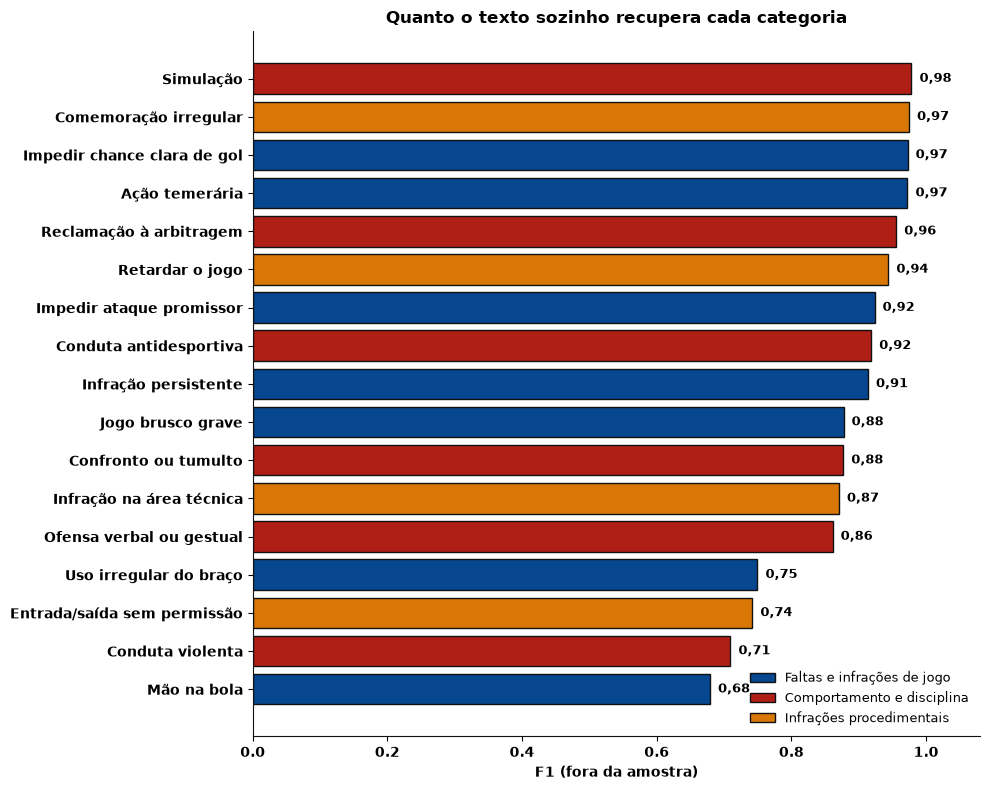

In [9]:
plot_order = tag_metrics.sort_values("f1", ascending=True)
colors = [FAMILY_COLORS[family] for family in plot_order["family"]]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_order["label"], plot_order["f1"], color=colors, edgecolor=INK)
for y, value in enumerate(plot_order["f1"]):
    ax.text(value + .012, y, f"{value:.2f}".replace(".", ","), va="center", fontweight="bold", fontsize=9)
ax.set_xlim(0, 1.08)
ax.set_xlabel("F1 (out of sample)")
ax.set_title("How well text alone recovers each category")
handles = [plt.Rectangle((0, 0), 1, 1, color=color, ec=INK) for color in FAMILY_COLORS.values()]
ax.legend(handles, FAMILY_COLORS.keys(), frameon=False, loc="lower right", fontsize=9)
style_axis(ax)
fig.tight_layout()
fig.savefig(VIZ_DIR / "5_01_f1_por_categoria.png", dpi=300, bbox_inches="tight")
plt.show()

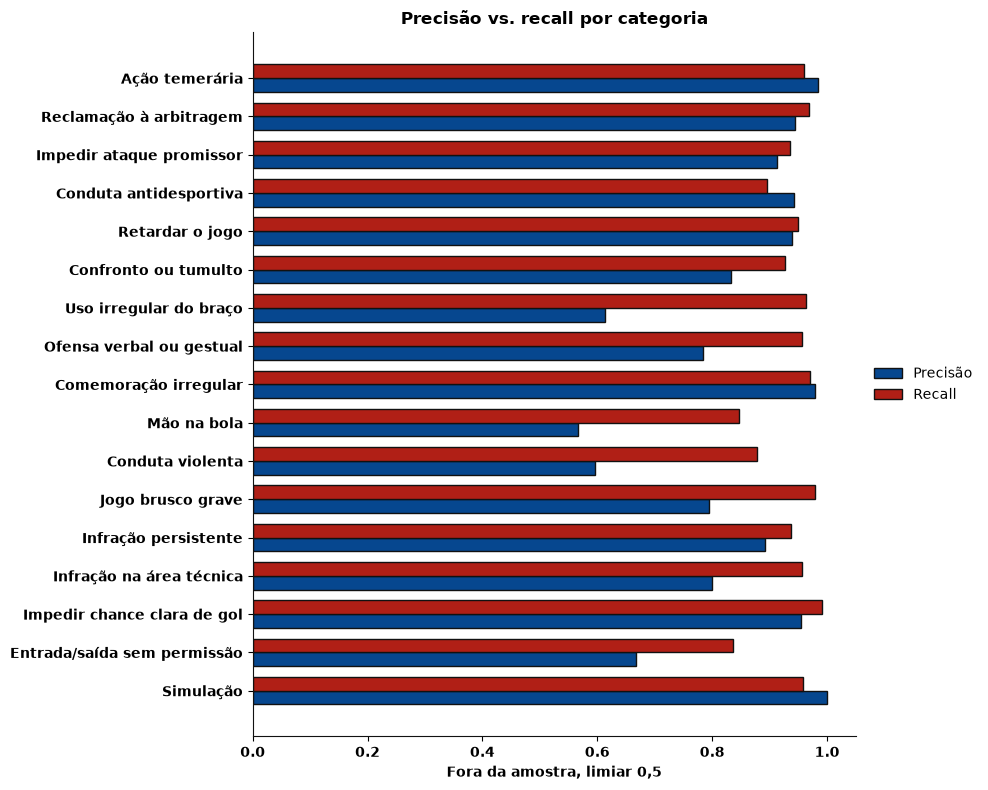

In [10]:
plot_order = tag_metrics.sort_values("n_eventos", ascending=True)
y = np.arange(len(plot_order))
height = 0.36

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(y - height / 2, plot_order["precisao"], height, color=BLUE, edgecolor=INK, label="Precision")
ax.barh(y + height / 2, plot_order["recall"], height, color=RED, edgecolor=INK, label="Recall")
ax.set_yticks(y)
ax.set_yticklabels(plot_order["label"])
ax.set_xlim(0, 1.05)
ax.set_xlabel("Out of sample, 0.5 threshold")
ax.set_title("Precision vs. recall by category")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
style_axis(ax)
fig.tight_layout()
fig.savefig(VIZ_DIR / "5_02_precisao_recall_por_categoria.png", dpi=300, bbox_inches="tight")
plt.show()

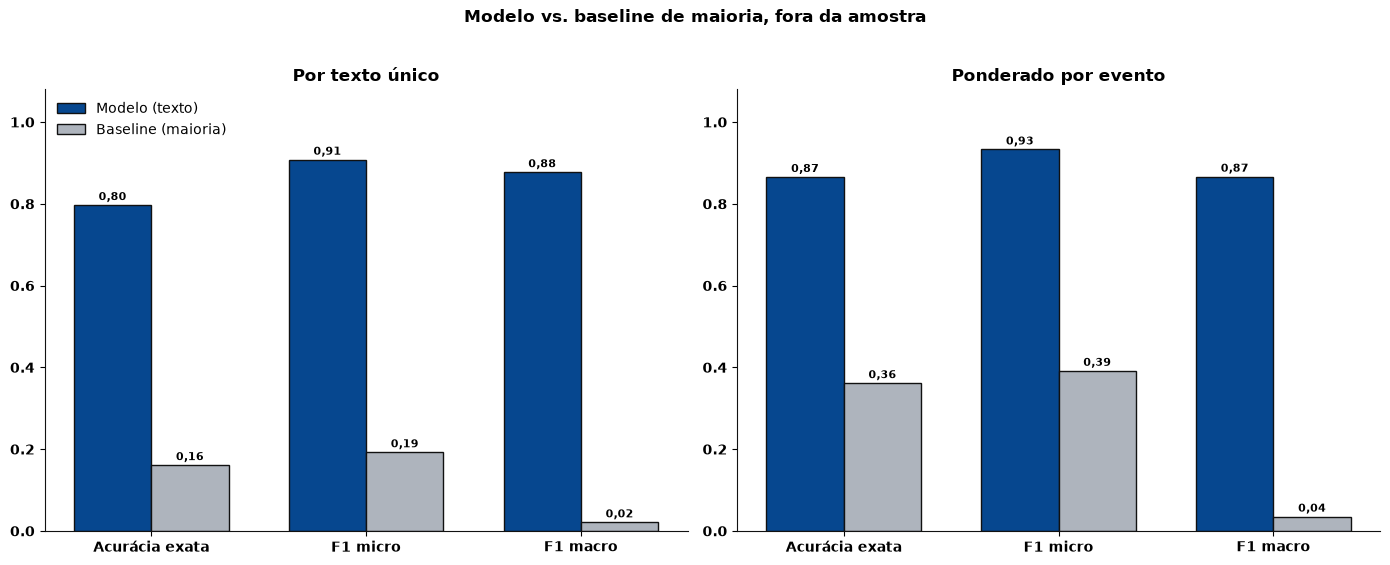

In [11]:
metric_labels = {"acuracia_exata": "Exact-match accuracy", "f1_micro": "Micro F1", "f1_macro": "Macro F1"}
metrics_to_plot = list(metric_labels)
weight_panels = [("texto_unico", "By unique text"), ("ponderado_evento", "Weighted by event")]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (weight_name, weight_title) in zip(axes, weight_panels):
    panel = global_df.loc[global_df["peso"].eq(weight_name)].set_index("modelo")
    x = np.arange(len(metrics_to_plot))
    width = 0.36
    model_bars = ax.bar(x - width / 2, panel.loc["modelo", metrics_to_plot], width,
                         color=BLUE, edgecolor=INK, label="Model (text)")
    baseline_bars = ax.bar(x + width / 2, panel.loc["baseline_maioria", metrics_to_plot], width,
                            color="#aeb4bd", edgecolor=INK, label="Baseline (majority)")
    for bars in (model_bars, baseline_bars):
        for bar in bars:
            value = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, value + .012, f"{value:.2f}".replace(".", ","),
                    ha="center", fontweight="bold", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([metric_labels[m] for m in metrics_to_plot])
    ax.set_ylim(0, 1.08)
    ax.set_title(weight_title)
    style_axis(ax)
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Model vs. majority baseline, out of sample", fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(VIZ_DIR / "5_03_acuracia_global.png", dpi=300, bbox_inches="tight")
plt.show()

## **7. Error audit**

False positives and false negatives by category, following the same audit-queue logic as `unclassified_texts.csv` in notebook `02`: the larger the `event_count`, the greater the practical impact of the error if the category were determined from text alone.

In [13]:
error_rows = []
for i, tag in enumerate(SEMANTIC_TAGS):
    false_positive = (~Y[:, i]) & oof_pred[:, i]
    false_negative = Y[:, i] & (~oof_pred[:, i])
    for error_type, mask in [("falso_positivo", false_positive), ("falso_negativo", false_negative)]:
        for idx in np.where(mask)[0]:
            error_rows.append({
                "reason_key": texts.iloc[idx]["reason_key"],
                "reason": texts.iloc[idx]["reason"],
                "event_count": int(texts.iloc[idx]["event_count"]),
                "tag": tag,
                "tag_label": TAG_LABELS[tag],
                "error_type": error_type,
                "proba": float(oof_proba[idx, i]),
            })

errors_df = pd.DataFrame(error_rows).sort_values("event_count", ascending=False).reset_index(drop=True)
errors_df.to_csv(OUTPUT_DIR / "misclassified_texts.csv", index=False)
print(f"{len(errors_df)} category errors across {errors_df['reason_key'].nunique()} texts")
display(errors_df.head(30))

1036 category errors across 857 texts


,reason_key,reason,event_count,tag,tag_label,error_type,proba
0,dar entrada temeraria adversario disputa bola,dar entrada temeraria adversario disputa bola,324,RECLAMAR_ARBITRAGEM,Reclamação à arbitragem,falso_negativo,0.001436
1,impedir ataque promissor,impedir ataque promissor,125,MAO_ANTIDESPORTIVA,Mão na bola,falso_negativo,0.213527
2,impedir ataque promissor,impedir ataque promissor,125,CONDUTA_ANTIDESPORTIVA,Conduta antidesportiva,falso_negativo,0.010208
3,dar entrada temeraria contra adversario disput...,dar entrada temeraria contra adversario disput...,88,FALTA_TATICA,Impedir ataque promissor,falso_negativo,0.012077
4,reclamar forma acintosa contra decisoes arbitr...,reclamar forma acintosa contra decisoes arbitr...,63,RETARDAR_REINICIO,Retardar o jogo,falso_negativo,0.010891
5,segurar adversario mostrando desrespeito jogo,segurar adversario mostrando desrespeito jogo,33,FALTA_TATICA,Impedir ataque promissor,falso_negativo,0.292405
6,cometer falta impedindo ataque promissor,cometer falta impedindo ataque promissor,33,MAO_ANTIDESPORTIVA,Mão na bola,falso_positivo,0.529027
7,segurar adversario forma acintosa,segurar adversario forma acintosa,28,FALTA_TATICA,Impedir ataque promissor,falso_positivo,0.827939
8,desaprovar decisoes arbitragem,desaprovar decisoes arbitragem,28,CONDUTA_ANTIDESPORTIVA,Conduta antidesportiva,falso_negativo,0.010395
9,impedir ataque promissor equipe adversaria,impedir ataque promissor equipe adversaria,27,MAO_ANTIDESPORTIVA,Mão na bola,falso_positivo,0.620671


## **8. Export**

Records the experiment configuration alongside the global metrics, following the same pattern as `keyword_tags/run_manifest.json` and `var_usage/run_manifest.json`, so that every result cited here can be traced to the model version that produced it.

In [14]:
run_manifest = {
    "generated_at": pd.Timestamp.now().isoformat(),
    "n_texts": len(texts),
    "n_tags": len(SEMANTIC_TAGS),
    "cross_validation": {"strategy": "MultilabelStratifiedKFold", "n_folds": N_FOLDS, "seed": SEED},
    "model": {
        "vectorizers": ["tfidf word (1,2)-gram min_df=2", "tfidf char_wb (3,5)-gram min_df=2"],
        "classifier": "OneVsRestClassifier(LogisticRegression(class_weight='balanced'))",
        "threshold": THRESHOLD,
    },
    "baseline_tag": baseline_tag,
    "global_metrics": global_df.to_dict(orient="records"),
}
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("saved", OUTPUT_DIR / "run_manifest.json")

saved /Users/gabrielcarbinatto/Documents/GitHub/cbf-match-report-analysis/data/processed/classification_validation/run_manifest.json
